### Capacitação em Processamento Digital de Sinais - VIRTUS CC
Orientador: Edson Porto

Aluno: Lucas de Souza Salvino


### Relatório 2: Transformadas Discretas

Objetivos:
1. Implementar DFT/IDFT manualmente e verificar suas propriedades (ver tabela de propriedades nos slides). 

2. Implementar a convolução linear a partir da convolução circular utilizando a DFT/IDFT.

3. Implementar os métodos overlap-and-add e overlap and save para o cálculo de convoluções lineares via DFT/IDFT.

4. Implementar o algoritmo da FFT e comparar tempo de execução e resultado com a DFT




## #1

**Transformada de Fourier Discreta (DFT)**: A definição clássica da transformada de Fourier não serve para o processamento de sinais no tempo discreto em computadores digitais, pois essa caracterização no domínio da frequência depende de uma variável contínua $\omega$. 

Para resolver isso, precisamos de uma transformada baseada em uma variável de frequência discreta, o que é feito amostrando uniformemente a variável de frequência contínua $\omega$. A DFT, portanto, faz o mapeamento de um sinal que depende de uma variável discreta de tempo $n$ numa transformada que depende de uma variável discreta de frequência $k$.

Ela atua como uma representação na frequência discreta para sinais de comprimento finito, mapeando um sinal $x(n)$ de comprimento $N$ em $N$ coeficientes na frequência.

$X(k) = \sum_{n=0}^{N-1} x(n)e^{-j(2\pi/N)kn}$ **(DFT)**

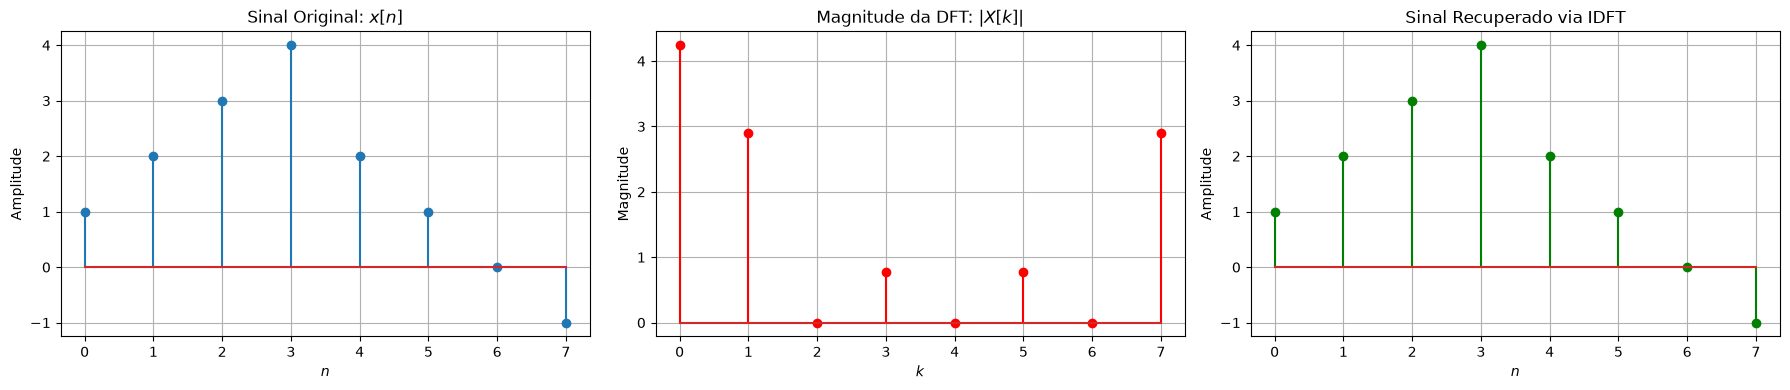

Erro máximo: 2.3314683517128287e-15


In [2]:

import numpy as np
import matplotlib.pyplot as plt

def DFT(x):
    """Calcula a DFT manualmente."""
    N = len(x)
    X = np.zeros(N, dtype=complex)

    for k in range(N):
        for n in range(N):
            X[k] += x[n] * np.exp(-1j * 2 * np.pi * k * n / N)

    return X / np.sqrt(N)


def IDFT(X):
    """Calcula a IDFT manualmente."""
    N = len(X)
    x = np.zeros(N, dtype=complex)

    for n in range(N):
        for k in range(N):
            x[n] += X[k] * np.exp(1j * 2 * np.pi * k * n / N)

    return x / np.sqrt(N)


# Sinal original
x_orig = np.array([1.0, 2.0, 3.0, 4.0, 2.0, 1.0, 0.0, -1.0])
n_idx = np.arange(len(x_orig))

# Transformações
X_k = DFT(x_orig)
x_rec = np.real(IDFT(X_k))

# Visualização
fig, axs = plt.subplots(1, 3, figsize=(18, 4))

axs[0].stem(n_idx, x_orig)
axs[0].set_title("Sinal Original: $x[n]$")
axs[0].set_xlabel("$n$")
axs[0].set_ylabel("Amplitude")
axs[0].grid(True)

axs[1].stem(n_idx, np.abs(X_k), linefmt="r-", markerfmt="ro")
axs[1].set_title("Magnitude da DFT: $|X[k]|$")
axs[1].set_xlabel("$k$")
axs[1].set_ylabel("Magnitude")
axs[1].grid(True)

axs[2].stem(n_idx, x_rec, linefmt="g-", markerfmt="go")
axs[2].set_title("Sinal Recuperado via IDFT")
axs[2].set_xlabel("$n$")
axs[2].set_ylabel("Amplitude")
axs[2].grid(True)

plt.tight_layout()
plt.show()

# Verificação numérica
print("Erro máximo:", np.max(np.abs(x_orig - x_rec)))


**Transformada de Fourier Discreta Inversa (IDFT)**: A IDFT complementa a DFT e mostra de que forma um sinal no tempo discreto pode ser recuperado a partir de sua representação na frequência discreta.

$x(n) = \frac{1}{N}\sum_{k=0}^{N-1} X(k)e^{j(2\pi/N)kn}$ **(IDFT)**

In [ ]:
def calcular_idft(X):
    """
    Calcula a Transformada de Fourier Discreta Inversa (IDFT) de um espectro X(k).
    """
    N = len(X)
    # Inicializa o vetor do sinal temporal com números complexos
    x = np.zeros(N, dtype=complex)
    
    for n in range(N):
        for k in range(N):
            # Equação: x(n) = (1/N) * sum(X(k) * e^(j * (2*pi/N) * k * n))
            x[n] += X[k] * np.exp(1j * (2 * np.pi / N) * k * n)
            
        x[n] /= N
        
    return x

Sinal Original no Tempo (x[n]): [1. 2. 3. 4.]

Sinal no Domínio da Frequência (DFT - X[k]):
[10.+0.j -2.+2.j -2.-0.j -2.-2.j]

Sinal Recuperado no Tempo (IDFT - x[n]):
[1. 2. 3. 4.]


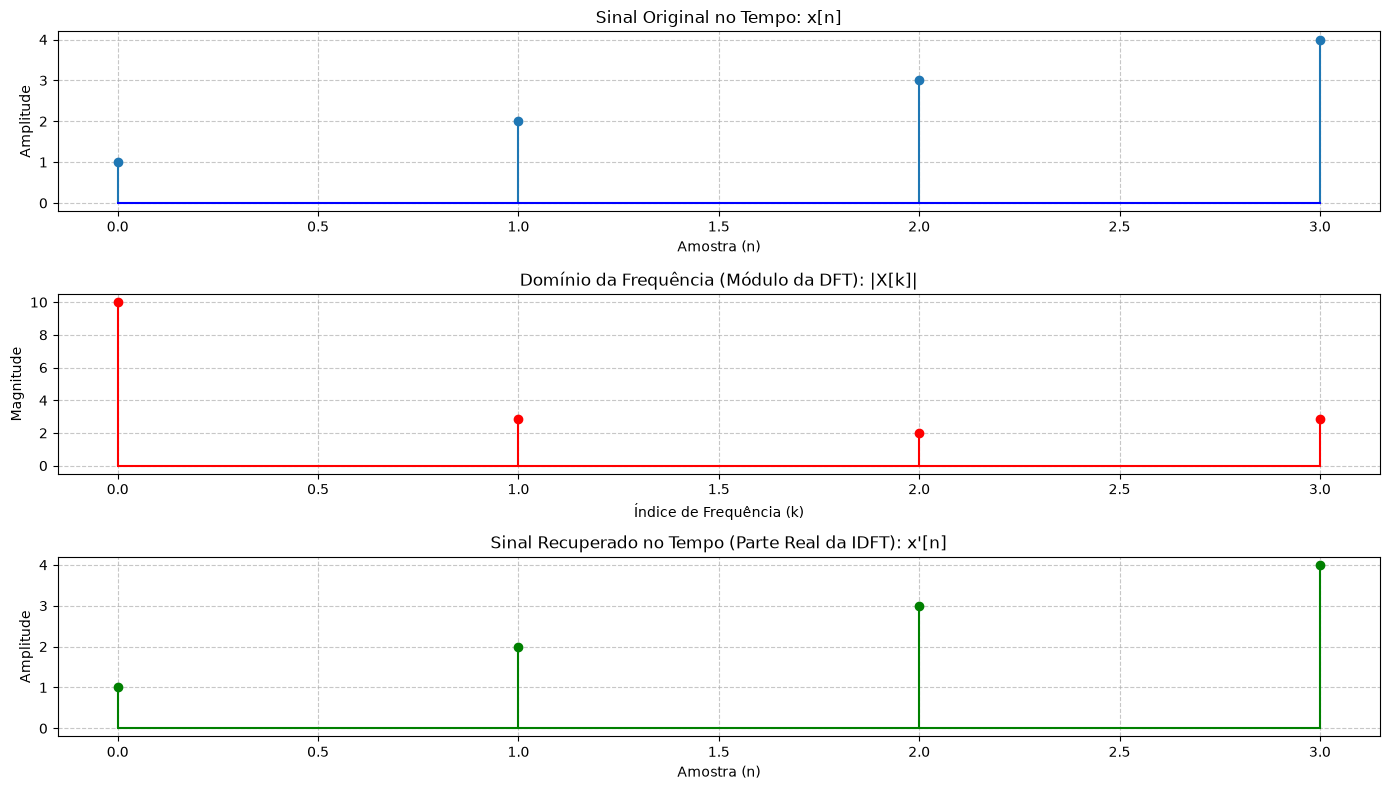

In [7]:

    # 1. Sinal discreto no tempo de comprimento N=4
    sinal_original = np.array([1.0, 2.0, 3.0, 4.0])
    n_amostras = np.arange(len(sinal_original))
    
    print("Sinal Original no Tempo (x[n]):", sinal_original)
    
    # 2. Calculando a DFT
    X_k = calcular_dft(sinal_original)
    magnitude_X_k = np.abs(X_k) # Extraindo o módulo (magnitude) para o gráfico
    k_amostras = np.arange(len(X_k))
    
    print("\nSinal no Domínio da Frequência (DFT - X[k]):")
    print(np.round(X_k, 4))
    
    # 3. Calculando a IDFT para recuperar o sinal
    sinal_recuperado_complexo = calcular_idft(X_k)
    sinal_recuperado = np.real(sinal_recuperado_complexo) # Extraindo apenas a parte real
    
    print("\nSinal Recuperado no Tempo (IDFT - x[n]):")
    print(np.round(sinal_recuperado, 4))

    # --- Plotagens Gráficas ---
    plt.figure(figsize=(14, 8))

    # Subplot 1: Sinal Original
    plt.subplot(3, 1, 1)
    plt.stem(n_amostras, sinal_original, basefmt="b-")
    plt.title("Sinal Original no Tempo: x[n]")
    plt.xlabel("Amostra (n)")
    plt.ylabel("Amplitude")
    plt.grid(True, linestyle='--', alpha=0.7)

    # Subplot 2: Módulo da DFT
    plt.subplot(3, 1, 2)
    plt.stem(k_amostras, magnitude_X_k, linefmt='r-', markerfmt='ro', basefmt="r-")
    plt.title("Domínio da Frequência (Módulo da DFT): |X[k]|")
    plt.xlabel("Índice de Frequência (k)")
    plt.ylabel("Magnitude")
    plt.grid(True, linestyle='--', alpha=0.7)

    # Subplot 3: Sinal Recuperado (IDFT)
    plt.subplot(3, 1, 3)
    plt.stem(n_amostras, sinal_recuperado, linefmt='g-', markerfmt='go', basefmt="g-")
    plt.title("Sinal Recuperado no Tempo (Parte Real da IDFT): x'[n]")
    plt.xlabel("Amostra (n)")
    plt.ylabel("Amplitude")
    plt.grid(True, linestyle='--', alpha=0.7)

    # Ajusta o espaçamento entre os gráficos e exibe
    plt.tight_layout()
    plt.show()